## Import necessary libraries

In [21]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [56]:
%pip install scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 8.6 MB/s eta 0:00:00m eta 0:00:010:01:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 kB 3.5 MB/s eta 0:00:003.5 MB/s eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.4/22.4 MB 8.0 MB/s eta 0:00:00m eta 0:00:010:00:01

[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Import Dataset

In [22]:
 car_dataset = pd.read_csv("mtcars.csv")

### Data Understanding

### Perform initial investigation on the data

In [23]:
car_dataset.shape

(32, 12)

In [24]:
car_dataset.isna().sum()

model    0
mpg      0
cyl      0
disp     0
hp       0
drat     0
wt       0
qsec     0
vs       0
am       0
gear     0
carb     0
dtype: int64

In [6]:
car_dataset.dtypes

model     object
mpg      float64
cyl        int64
disp     float64
hp         int64
drat     float64
wt       float64
qsec     float64
vs         int64
am         int64
gear       int64
carb       int64
dtype: object

In [25]:
car_dataset.describe()

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
count,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.0000
mean,20.090625,6.187500,230.721875,146.687500,3.596563,3.217250,17.848750,0.437500,0.406250,3.687500,2.8125
std,6.026948,1.785922,123.938694,68.562868,0.534679,0.978457,1.786943,0.504016,0.498991,0.737804,1.6152
min,10.400000,4.000000,71.100000,52.000000,2.760000,1.513000,14.500000,0.000000,0.000000,3.000000,1.0000
25%,15.425000,4.000000,120.825000,96.500000,3.080000,2.581250,16.892500,0.000000,0.000000,3.000000,2.0000
50%,19.200000,6.000000,196.300000,123.000000,3.695000,3.325000,17.710000,0.000000,0.000000,4.000000,2.0000
75%,22.800000,8.000000,326.000000,180.000000,3.920000,3.610000,18.900000,1.000000,1.000000,4.000000,4.0000
max,33.900000,8.000000,472.000000,335.000000,4.930000,5.424000,22.900000,1.000000,1.000000,5.000000,8.0000


### In data understanding we need to check for assuptions 

### Test 1 : Linearity Test

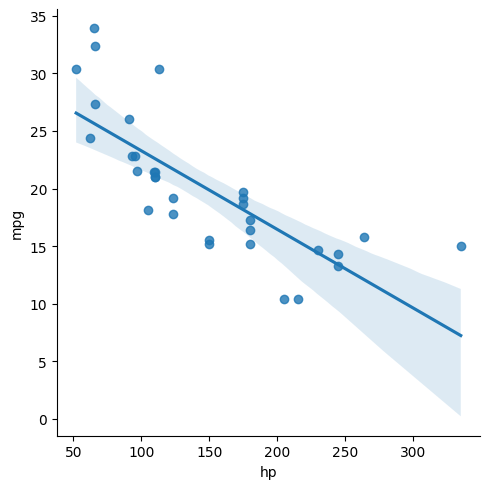

In [26]:
sns.lmplot(data = car_dataset,
    x="hp",
    y="mpg",)

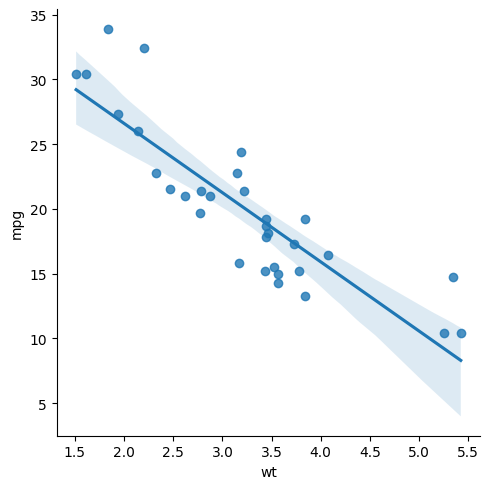

In [27]:
sns.lmplot(data = car_dataset,
    x="wt",
    y="mpg",)

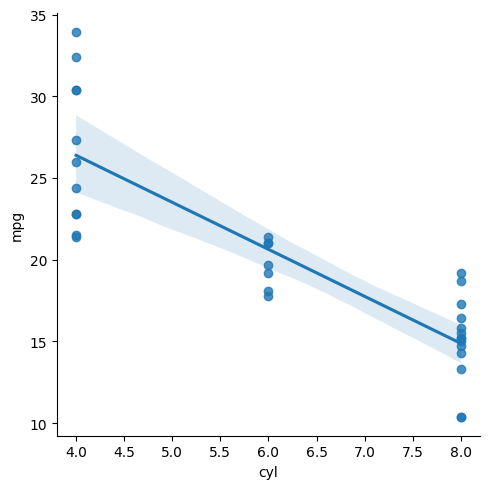

In [28]:
sns.lmplot(data = car_dataset,
    x="cyl",
    y="mpg",)

###  Test 1 - Linerity failed

## Normality Test



(array([3., 3., 3., 3., 9., 7., 1., 0., 0., 3.]),
 array([1.513 , 1.9041, 2.2952, 2.6863, 3.0774, 3.4685, 3.8596, 4.2507,
        4.6418, 5.0329, 5.424 ]),
 <BarContainer object of 10 artists>)

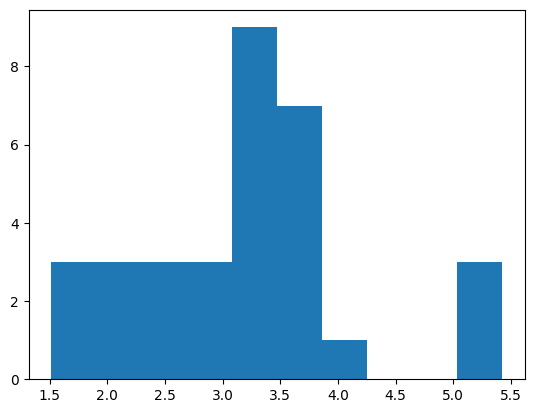

In [29]:
plt.hist(car_dataset["wt"])

plt.hist(car_dataset["hp"])

(array([6., 6., 4., 1., 1., 5., 3., 2., 1., 3.]),
 array([ 71.1 , 111.19, 151.28, 191.37, 231.46, 271.55, 311.64, 351.73,
        391.82, 431.91, 472.  ]),
 <BarContainer object of 10 artists>)

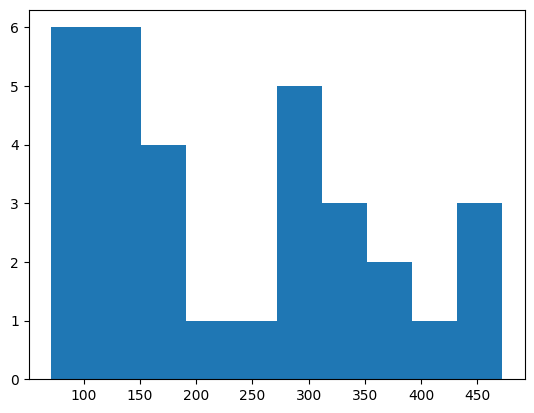

In [30]:
plt.hist(car_dataset["disp"])

## Test 2 Normality Failed

### Correlation test

In [31]:
corr_matrix = car_dataset[["wt","hp","cyl"]].corr()
corr_matrix

,wt,hp,cyl
wt,1.000000,0.658748,0.782496
hp,0.658748,1.000000,0.832447
cyl,0.782496,0.832447,1.000000


<Axes: >

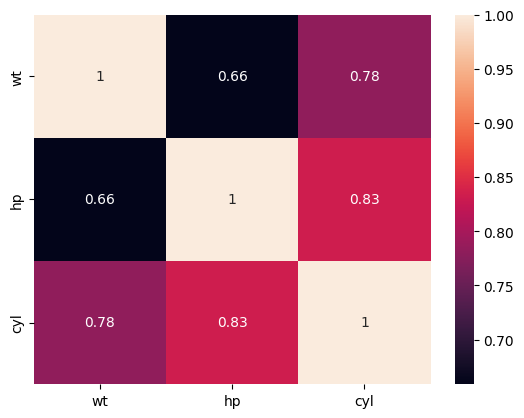

In [32]:
sns.heatmap(data = corr_matrix, annot = True)

### Test 3 : There is multicolinerarity in the Data

### Test 4 Auto regression passed - it should not contain any time based data

### Step 4 Data preparation

In [33]:
car_dataset.head()

,model,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
1,Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
2,Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
3,Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
4,Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2


In [34]:
car_dataset.drop(columns = ["model"])

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
1,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
2,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
3,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
4,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2
5,18.1,6,225.0,105,2.76,3.460,20.22,1,0,3,1
6,14.3,8,360.0,245,3.21,3.570,15.84,0,0,3,4
7,24.4,4,146.7,62,3.69,3.190,20.00,1,0,4,2
8,22.8,4,140.8,95,3.92,3.150,22.90,1,0,4,2
9,19.2,6,167.6,123,3.92,3.440,18.30,1,0,4,4


In [35]:
X= car_dataset[["cyl","disp","wt","hp"]]
X

,cyl,disp,wt,hp
0,6,160.0,2.620,110
1,6,160.0,2.875,110
2,4,108.0,2.320,93
3,6,258.0,3.215,110
4,8,360.0,3.440,175
5,6,225.0,3.460,105
6,8,360.0,3.570,245
7,4,146.7,3.190,62
8,4,140.8,3.150,95
9,6,167.6,3.440,123


In [36]:
y = car_dataset["mpg"] 
y

0     21.0
1     21.0
2     22.8
3     21.4
4     18.7
5     18.1
6     14.3
7     24.4
8     22.8
9     19.2
10    17.8
11    16.4
12    17.3
13    15.2
14    10.4
15    10.4
16    14.7
17    32.4
18    30.4
19    33.9
20    21.5
21    15.5
22    15.2
23    13.3
24    19.2
25    27.3
26    26.0
27    30.4
28    15.8
29    19.7
30    15.0
31    21.4
Name: mpg, dtype: float64

### Note: There is no need to do data prepartion when all feature/ column is numeric

# Step 5 Model Building - Linear regression

In [37]:
linear_model = LinearRegression()

# Step 6 Model Training

In [38]:
linear_model.fit(X,y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [42]:
linear_model.intercept_ # intercept is when x = 0 where y intercept

np.float64(40.82853674224322)

In [43]:
linear_model.coef_ # coefficient is slope

array([-1.29331972,  0.01159924, -3.85390352, -0.02053838])

# Step 7 Model Testing

In [45]:
y_predicted = linear_model.predict(X)
y_predicted

array([22.56804806, 21.58530266, 26.05685052, 21.41170091, 17.80606112,
       20.18741154, 15.86736731, 23.78953468, 23.19748889, 19.2290025 ,
       19.2290025 , 14.29875407, 15.60908127, 15.41638609, 11.51345925,
       10.4983054 , 10.26270335, 26.73399739, 29.2412705 , 28.07305633,
       25.5562318 , 17.5240402 , 17.68923264, 14.71082097, 16.70919976,
       27.7587616 , 26.93430055, 28.60655295, 16.91430642, 20.48097948,
       13.33455832, 24.10623099])

# Step 8 Model Evaluation



In [47]:
error= y - y_predicted
error

0    -1.568048
1    -0.585303
2    -3.256851
3    -0.011701
4     0.893939
5    -2.087412
6    -1.567367
7     0.610465
8    -0.397489
9    -0.029002
10   -1.429002
11    2.101246
12    1.690919
13   -0.216386
14   -1.113459
15   -0.098305
16    4.437297
17    5.666003
18    1.158729
19    5.826944
20   -4.056232
21   -2.024040
22   -2.489233
23   -1.410821
24    2.490800
25   -0.458762
26   -0.934301
27    1.793447
28   -1.114306
29   -0.780979
30    1.665442
31   -2.706231
Name: mpg, dtype: float64

### Now lets perform Test 5  Homoscedasticity.  Tests 5 & 6 only now these two tests can be perormed

<Axes: xlabel='hp', ylabel='mpg'>

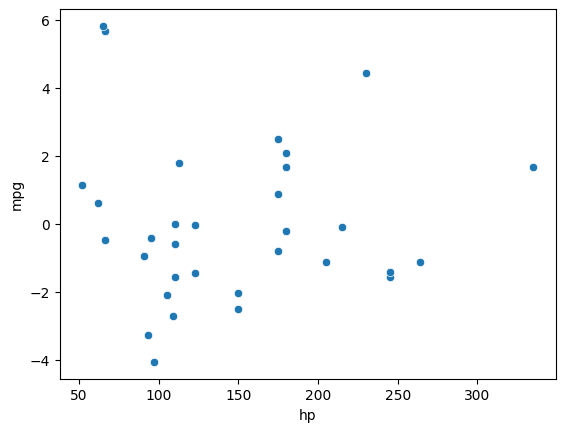

In [50]:
sns.scatterplot(data = car_dataset,x = "hp",y = error)

<Axes: xlabel='cyl', ylabel='mpg'>

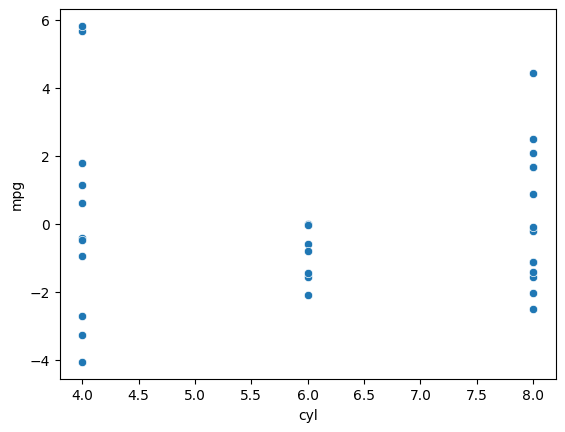

In [51]:
sns.scatterplot(data = car_dataset,x = "cyl",y = error)

<Axes: xlabel='wt', ylabel='mpg'>

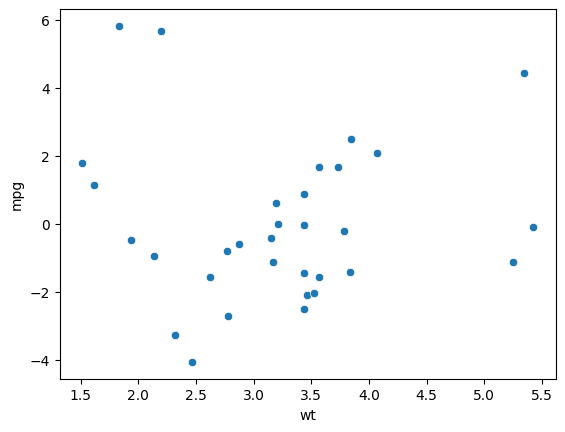

In [52]:
sns.scatterplot(data = car_dataset,x = "wt",y = error)

<Axes: xlabel='disp', ylabel='mpg'>

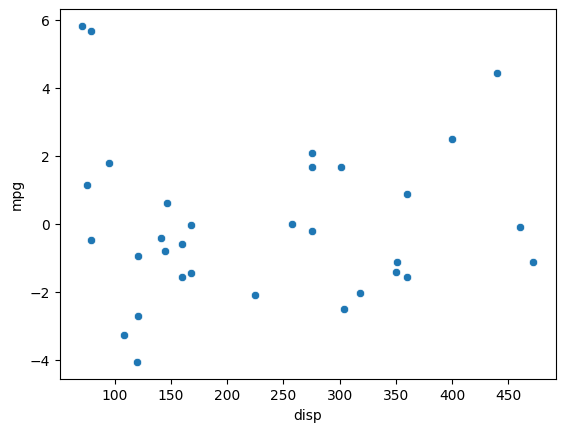

In [53]:
sns.scatterplot(data = car_dataset,x = "disp",y = error)

### Test 5 Homoscedasticity also failed

## Test 6 Zero residual Mean Test

<Axes: xlabel='mpg'>

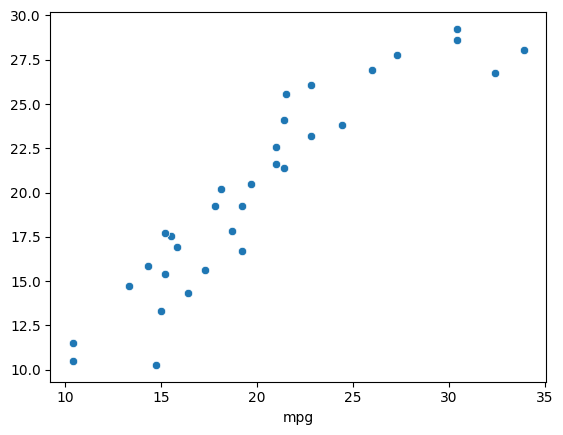

In [56]:
sns.scatterplot(x = car_dataset["mpg"], y = y_predicted )

### Test 6 Zero residual test is also failed

# 9. Model Deployment

In [57]:
from pickle import dump

In [60]:
dump(obj = linear_model,file = open(file = "linear_inteligence_file_pk1", mode = "wb"))

In [62]:
from pickle import load

In [66]:
linear_intl_pkl = load(file = open(file = "linear_inteligence_file_pk1", mode = "rb"))
linear_intl_pkl

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False
